# Breaking Frontier Lock
Score Dilution, Certificate Gating, and Online Operator Induction

**Yan Su · ARC Prize 2026 Paper Track**

Run all cells with Internet disabled and a CPU runtime. The notebook contains the 825 baseline observations,
250 paired confirmation observations, 30 official submission records, numerical table observations,
and the scoring, symmetry and production bridge code used below. Outputs include freshly computed scores,
survival hazards, paired tests, 768 group checks and 13 bridge contracts.

The submission mapping identifies the separate offline-GPU competition runs. Saved observations reproduce
their reported measurements; the cells recompute the analysis and run the algebraic and bridge tests.
Code: MIT-0. Manuscript tables retain their source attribution.

In [1]:
import base64, hashlib, io, json, math, os, sys, tempfile, time, types, zlib
from collections import defaultdict
from fractions import Fraction as F
from pathlib import Path
import numpy as np
import matplotlib
if 'get_ipython' in globals():
    get_ipython().run_line_magic('matplotlib', 'inline')
else:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
started = time.perf_counter()
checks = {}
float_differences = []
def compare_statistics(actual, expected, path):
    """Compare structure exactly and float leaves within 1e-12 across platforms."""
    def require(condition, detail):
        if not condition:
            raise AssertionError(f'{path}: {detail}; actual={actual!r}; expected={expected!r}')
    require(type(actual) is type(expected), 'type mismatch')
    if isinstance(expected, dict):
        require({(type(k), k) for k in actual} == {(type(k), k) for k in expected}, 'key mismatch')
        for key in expected:
            compare_statistics(actual[key], expected[key], path + '/' + str(key))
    elif isinstance(expected, (list, tuple)):
        require(len(actual) == len(expected), 'length mismatch')
        for i, (a, b) in enumerate(zip(actual, expected)):
            compare_statistics(a, b, path + '/' + str(i))
    elif isinstance(expected, float):
        require(math.isclose(actual, expected, rel_tol=1e-12, abs_tol=1e-12), 'float outside tolerance')
        if actual != expected:
            float_differences.append({'path': path, 'actual': actual, 'expected': expected})
    else:
        require(actual == expected, 'value mismatch')
checks['statistics_float_comparison'] = {'rel_tol': 1e-12, 'abs_tol': 1e-12, 'differences': float_differences}
import lzma, pickle
payload_bytes = lzma.decompress(base64.b64decode('...'))
assert hashlib.sha256(payload_bytes).hexdigest() == '8fa20e1f79f3a75e6454c2adbfe1974bda614e953c4fe9d6b7458bc123d06001'

D = pickle.loads(payload_bytes)
def install_module(name, source):
    mod = types.ModuleType(name)
    mod.__file__ = name + '.py'
    sys.modules[name] = mod
    exec(compile(source, mod.__file__, 'exec'), mod.__dict__)
    return mod
exec(D['modules']['common'])
inv = types.ModuleType('receipt_arithmetic')
inv.__dict__.update(F=F, math=math, time=time)
exec(D['modules']['inversion'], inv.__dict__)
print('Embedded observations:', sum(map(len, D['traces'].values())), 'baseline runs,',
      len(D['confirmation']), 'confirmation runs,', len(D['receipts']), 'official receipts')
print('External API calls: 0; external files: 0; GPU requirement: 0')

Embedded observations: 825 baseline runs, 250 confirmation runs, 30 official receipts
External API calls: 0; external files: 0; GPU requirement: 0


## 1. Triangular scorer and completion-share cap
Level weight is its one-based index. A completed level earns min(115,100(b/a)²), with the game score
capped by 100 times the completed positive-score weight share. An exact rational implementation
and the trace-analysis implementation are evaluated independently.

In [2]:
scorer_cases = 0
max_formula_error = 0.0
for L in range(1, 11):
    for k in range(L + 1):
        for actions_ in (1, 10, 20, 100):
            a = [actions_] * L
            b = [20] * L
            exact = inv.game_score(b, a, [i < k for i in range(L)])
            computed = score(L, k, a, b)
            max_formula_error = max(max_formula_error, abs(float(exact) - computed))
            assert computed <= depth_cap(k, L) + 1e-12
            scorer_cases += 1
assert max_formula_error < 1e-12
assert inv.game_score([0], [1], [True]) == 0
assert inv.game_score([1], [0], [True]) == 0
checks['scorer'] = {'cases': scorer_cases + 2, 'max_formula_error': max_formula_error}
print(f'Formula checks: {scorer_cases + 2}; maximum error: {max_formula_error:.2f}')
print('A1: dataset | runs | max recorded-score difference | mean recorded | mean recomputed')
for name, rows in D['traces'].items():
    recomputed = [score(r['L'], r['k'], r['a'], r['base']) for r in rows]
    err = max(abs(s-r['score']) for s, r in zip(recomputed, rows))
    print(f"{name:20} {len(rows):4} {err:8.4f} {np.mean([r['score'] for r in rows]):8.3f} {np.mean(recomputed):8.3f}")
    assert abs(err - D['analysis']['a1_scorer'][name]['max_abs_err']) < 1e-10
print('The gpt-oss source records contain two score discrepancies; A1 preserves both observations.')

Formula checks: 262; maximum error: 0.00
A1: dataset | runs | max recorded-score difference | mean recorded | mean recomputed
kaggle_v2              25   0.0000    8.796    8.796
kaggle_v3              25   0.0000    3.123    3.123
kaggle_v4              25   0.0000    6.379    6.379
kaggle_v5              25   0.0000    7.295    7.295
kaggle_v7              25   0.0000    1.367    1.367
api_qwen38flash       125   0.0000    9.066    9.066
tufa_qwen36_27b       500   0.0000    1.600    1.600
api_gptoss120b         75   2.7778    0.160    0.232
The gpt-oss source records contain two score discrepancies; A1 preserves both observations.


## 2. Frontier Lock, survival hazard and paired confirmation
Kaplan-Meier treats the final unsolved level as right-censored. Hazards below are recomputed from
the embedded observations. Confirmation pairs are grouped by the same 25 games, with five repeats per arm.

In [3]:
hazard = {}
print('A2/A3: dataset | frontier action share | attempts | h(0), h(20), h(40), h(80), h(160)')
for name, runs in D['traces'].items():
    total = sum(sum(r['a']) for r in runs)
    frontier = sum(r['a'][r['k']] for r in runs if r['k'] < r['L'])
    rows = [r for r in attempts(runs) if r[3] or r[2] > 0]
    dur = np.array([r[2] for r in rows]); events = np.array([r[3] for r in rows])
    hazard[name] = [cond_pass(dur, events, n, 20) for n in (0,20,40,80,160)]
    expected = D['analysis']['a3_hazard']['actions'][name]
    for n,h in zip((0,20,40,80,160), hazard[name]):
        e = expected['cond_pass_next20'][str(n)][0]
        assert (h is None and e is None) or (h is not None and e is not None and abs(h-e)<1e-12)
    assert total == D['analysis']['a2_frontier_lock'][name]['actions']
    assert frontier == D['analysis']['a2_frontier_lock'][name]['frontier_actions']
    print(name, f'{100*frontier/total:.1f}%', len(rows),
          ', '.join('NA' if h is None else f'{h:.3f}' for h in hazard[name]))
assert sum(map(len,D['traces'].values())) == 825
checks['hazard'] = {'runs':825,'datasets':len(hazard),'point_checks':40}
arms = {a: [r for r in D['confirmation'] if r['arm']==a] for a in ('base','early')}
assert all(len(rows)==125 for rows in arms.values())
games = sorted({r['game'] for r in arms['base']})
assert len(games)==25
assert all(sum(r['game']==g for r in arms[a])==5 for a in arms for g in games)
net_clears = sum(r['k'] for r in arms['early'])-sum(r['k'] for r in arms['base'])
net_actions = sum(r['actions'] for r in arms['early'])-sum(r['actions'] for r in arms['base'])
delta = net_clears / 125
assert net_clears == -16 and net_actions == -2172 and delta == -0.128
import random, statistics as st
paired_results = {}
for field in ('k','score_rounded'):
    differences = [st.mean(r[field] for r in arms['early'] if r['game']==g) -
                   st.mean(r[field] for r in arms['base'] if r['game']==g) for g in games]
    rng = random.Random(0)
    values = np.asarray(differences)
    # Same Random(0) choices and game-cluster bootstrap as the original 20,000 replicates.
    # random.choice uses randbelow; reproduce the source exactly rather than choices().
    rng = random.Random(0)
    indices = np.fromiter((rng.randrange(25) for _ in range(20000*25)), dtype=int).reshape(20000,25)
    boots = np.sort(values[indices].mean(axis=1))
    paired_results[field] = [st.mean(differences), float(boots[500]),float(boots[19500])]
    key = 'levels' if field=='k' else 'score'
    ref = D['analysis']['a8_confirmation'][key]
    assert np.allclose(paired_results[field], [ref['difference'], *ref['ci95']], atol=1e-12)
    print(field, 'paired difference and 95% game-bootstrap CI:', paired_results[field])
print(f'250-run confirmation: {delta:+.3f} levels/game; {net_clears:+d} net clears; {net_actions:+d} actions')
checks['confirmation'] = {'runs':250,'delta_levels':delta,'net_clears':net_clears,'net_actions':net_actions}

A2/A3: dataset | frontier action share | attempts | h(0), h(20), h(40), h(80), h(160)
kaggle_v2 68.9% 67 0.272, 0.298, 0.093, 0.000, 0.000
kaggle_v3 62.2% 45 0.225, 0.360, 0.259, 0.000, NA
kaggle_v4 64.9% 56 0.313, 0.168, 0.289, 0.091, 0.000
kaggle_v5 66.4% 58 0.267, 0.312, 0.215, 0.000, 0.000
kaggle_v7 60.3% 37 0.414, 0.167, 0.667, NA, NA
api_qwen38flash 52.4% 310 0.276, 0.334, 0.308, 0.085, 0.000
tufa_qwen36_27b 82.9% 806 0.164, 0.126, 0.084, 0.054, 0.010
api_gptoss120b 99.4% 70 0.060, 0.034, 0.000, 0.000, 0.000
k paired difference and 95% game-bootstrap CI: [-0.128, -0.312, 0.048000000000000036]
score_rounded paired difference and 95% game-bootstrap CI: [0.3578400000000002, -1.0662399999999996, 1.9528800000000004]
250-run confirmation: -0.128 levels/game; -16 net clears; -2172 actions


## 3. D₄ equivariant transfer
These are the production pixel, coordinate and action transforms. For each of the 64 group compositions,
the notebook checks four directions and eight board-click locations: 768 equivariance assertions.

In [4]:
exec(D['modules']['d4'])
def mul(a,b):
    return tuple(tuple(sum(a[i][k]*b[k][j] for k in range(2)) for j in range(2)) for i in range(2))
box = (0,0,7,7)
board = np.arange(64).reshape(8,8)
points = [(0,0),(7,0),(0,7),(7,7),(1,3),(5,2),(3,4),(6,5)]
group_checks = 0
for i in range(8):
    for j in range(8):
        k = _MATRICES.index(mul(_MATRICES[i],_MATRICES[j]))
        assert np.array_equal(d4_pixels(d4_pixels(board,j),i),d4_pixels(board,k))
        for a in ('UP','DOWN','LEFT','RIGHT'):
            assert d4_action(d4_action(a,box,j),box,i) == d4_action(a,box,k)
            group_checks += 1
        for x,y in points:
            assert d4_point(*d4_point(x,y,box,j),box,i) == d4_point(x,y,box,k)
            assert d4_action(d4_action(mouse(x,y),box,j),box,i) == d4_action(mouse(x,y),box,k)
            group_checks += 1
for i in range(8):
    assert d4_action(mouse(3,0),box,i,hud_mask=((0,3),)) == mouse(3,0)
assert group_checks == 768
checks['d4'] = {'group_order':8,'homomorphism_checks':group_checks,'passed':True}
print(f'D4: {group_checks}/{group_checks} homomorphism checks; 64 pixel-composition checks; 8 fixed-HUD checks')

D4: 768/768 homomorphism checks; 64 pixel-composition checks; 8 fixed-HUD checks


## 4. Official receipt differentials and submission mapping
All 30 records are embedded. Fraction arithmetic preserves each reported decimal exactly.
Conditional lattice solutions use disjoint full-game gains/losses and at most one partial prefix loss,
with the displayed-score rounding interval. Each row prints its model assumptions with the solution count.

In [5]:
receipts = {r['ref']:r for r in D['receipts']}
assert len(receipts)==30
print('ref | date | status | reported leaderboard score')
for r in D['receipts']:
    print(r['ref'],r['date'],r['status'],r['score'])
mapping = {57031236:28.38,56751129:27.20,57827241:25.70,57894564:21.08}
print('\nMain-track submission mapping')
for ref,value in mapping.items():
    assert receipts[ref]['score']==value
    print(f'#{ref}: {value:.2f}  https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3/submissions?tab=public')
cases = [(57774685,57827241,'-16.31'),(57786717,57827241,'-17.98'),
         (57854657,57827241,'-4.94'),(57894564,57854657,'0.32'),(57894564,57827241,'-4.62')]
inversions = []
for new,old,expected in cases:
    result = inv.invert_score(str(receipts[new]['score']),str(receipts[old]['score']),enumerate_lattice=True)
    assert F(result['delta_points']['exact'])==F(expected)
    lattice = result['conditional_lattice']
    print(f"#{new} vs #{old}: {float(F(expected)):+.2f} = {F(expected)}; "
          f"net game equivalents={result['net_full_game_equivalents']['exact']}; "
          f"minimum changed games={result['minimum_games_with_changed_scores']}; "
          f"conditional solutions={lattice['solutions_count']}")
    inversions.append(result)
print('Lattice assumptions:', '; '.join(lattice['assumptions']))
print(f'Hidden-set ratio: {28.38/3.41:.2f}x')
checks['receipts'] = {'records':30,'exact_differentials':5,'submission_mapping':mapping}

ref | date | status | reported leaderboard score
56374698 2026-09-20 COMPLETE 2.93
56408484 2026-09-21 COMPLETE 3.22
56547792 2026-09-25 COMPLETE 2.51
56563323 2026-09-26 ERROR None
56595946 2026-09-27 COMPLETE 2.51
56623459 2026-09-28 COMPLETE 0.99
56656982 2026-09-29 COMPLETE 3.41
56702094 2026-09-30 COMPLETE 2.6
56751129 2026-10-01 COMPLETE 27.2
56767431 2026-10-02 COMPLETE 1.59
56789456 2026-10-03 COMPLETE 3.13
56837065 2026-10-05 COMPLETE 25.83
56877896 2026-10-06 COMPLETE 23.49
56901733 2026-10-07 COMPLETE 26.04
56927381 2026-10-08 COMPLETE 24.12
56980083 2026-10-09 COMPLETE 24.13
57031236 2026-10-10 COMPLETE 28.38
57059845 2026-10-11 COMPLETE 21.39
57088910 2026-10-12 COMPLETE 23.33
57123146 2026-10-13 COMPLETE 23.72
57160178 2026-10-14 COMPLETE 21.22
57252762 2026-10-16 COMPLETE 26.58
57302014 2026-10-17 COMPLETE 0.0
57329763 2026-10-18 COMPLETE 26.55
57774685 2026-10-29 COMPLETE 9.39
57786717 2026-10-30 COMPLETE 7.72
57821023 2026-10-31 ERROR None
57827241 2026-10-31 COMPLETE 

## 5. One-way gate: 13 production-bridge contracts
The fixture runs the embedded production host wrapper. Uncertified paths execute zero host actions,
certified traces cross levels, and a returned level stays with the coding model until completion.

In [6]:
for name in ('sandbox_autosearch','giants_sandbox_bridge'):
    install_module(name,D['modules'][name])
exec(D['modules']['host_fixture'])
gate_rows = host_burst_check()
assert len(gate_rows)==13
compare_statistics(gate_rows, D['host_fixture_observation'], 'host_fixture')
for name,result in gate_rows.items():
    print(name,json.dumps(result,sort_keys=True))
checks['certificate_gate'] = {'contracts':len(gate_rows),'passed':True}
print('Certificate gate: 13/13 production-bridge contracts passed')

open_probe {"hint_reason": "safe border sweep", "host_moves": 0, "locked_level": 0, "no_burst_reasons": ["context graph motion frontier", "context graph navigate to foreground", "interactive directed_wire", "interactive fetch", "observed floor route to rare object", "observed object adjacency interaction", "observed row sort", "observed selection and motion macro", "safe border sweep", "safe interior sweep", "single frame safe fallback", "terminal recovery", "unrecognized observation"]}
heuristic_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
queued_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
base_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
push_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
symmetry_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
near_replay_zero_probe {"host_moves": 0, "locked_level": 0, "model_moves": 1}
wrong_replay_zero_probe {"host_moves": 0, "locked_level": 0, "mo

## 6. Thread-clock calibration
The measured 10-thread observations are preserved below. Their inflation ratios and single/ten-thread
action identity are verified. A short live two-thread probe additionally exercises this runtime's clocks;
the measured 9.73x ratio belongs to the archived 10-thread experiment.

In [7]:
measured = {'thread_cpu_s':0.0263,'process_cpu_s':0.2558,'wall_s':0.2570,'threads':10}
process_ratio = measured['process_cpu_s']/measured['thread_cpu_s']
wall_ratio = measured['wall_s']/measured['thread_cpu_s']
assert round(process_ratio,2)==9.73 and round(wall_ratio,2)==9.77
G = D['gil_observation']
assert G['threads']==10
for game in ('su15','sk48'):
    single, concurrent = G['single_thread'][game],G['ten_threads'][game]
    assert single['win'] and concurrent['win']
    assert single['actions_sha256']==concurrent['actions_sha256']
    assert single['steps']==concurrent['steps']
    print(game, 'single/10-thread action identity:',single['steps'],'steps;',
          concurrent['levels'],'levels; thread CPU:',concurrent['thread_cpu_s'])
assert len(G['clock_scan'])==14
assert all(r['thread_clock'] and not r['violations'] and not r['unsorted_set_loops'] for r in G['clock_scan'].values())
print('10-thread measured process/thread inflation:',f'{process_ratio:.2f}x')
print('10-thread measured wall/thread inflation:',f'{wall_ratio:.2f}x')
print('Cloud-core 2.5x factor times inflation:',f'{2.5*process_ratio:.2f}x')
import threading
barrier = threading.Barrier(2)
live = []
def clock_probe():
    barrier.wait()
    t0,p0,w0 = time.thread_time(),time.process_time(),time.perf_counter()
    n = 0
    while time.thread_time()-t0 < 0.02:
        n += 1
    live.append({'thread_cpu_s':time.thread_time()-t0,'process_cpu_s':time.process_time()-p0,
                 'wall_s':time.perf_counter()-w0})
threads = [threading.Thread(target=clock_probe) for _ in range(2)]
for t in threads:t.start()
for t in threads:t.join()
assert len(live)==2 and all(r['thread_cpu_s']>=0.02 for r in live)
print('Live two-thread clock probe:',json.dumps(live))
checks['thread_clock'] = {'archived_threads':10,'process_inflation':process_ratio,
                          'action_identity_games':2,'modules_checked':14,'live_probe_threads':2}

su15 single/10-thread action identity: 83 steps; 9 levels; thread CPU: 2.181
sk48 single/10-thread action identity: 265 steps; 8 levels; thread CPU: 2.742
10-thread measured process/thread inflation: 9.73x
10-thread measured wall/thread inflation: 9.77x
Cloud-core 2.5x factor times inflation: 24.32x
Live two-thread clock probe: [{"thread_cpu_s": 0.020001916, "process_cpu_s": 0.032249999999999446, "wall_s": 0.03298945806454867}, {"thread_cpu_s": 0.020001292, "process_cpu_s": 0.04007799999999939, "wall_s": 0.04096037498675287}]


## 7. Core paper tables
The manuscript's 15 complete tables are included below, followed by the suite completion ratios.
Sections 1 through 6 recompute the scoring, hazard, confirmation, symmetry, receipt and gate readings
from embedded observations. Confidence intervals and comparison rows below retain their measured source values.

In [8]:
assert len(D['tables'])==15
for i,table in enumerate(D['tables'],1):
    print(f'\nTABLE {i} / 15\n{table}')
K1 = next(t for t in D['tables'] if 'Turducken-49' in t and '396 / 396' in t)
suites = [('Public-25',25,183,183,25),('Parametric-25',25,172,172,25),('Tufa-50',50,232,232,50),
          ('Clone-118',118,551,552,99),('Held-Out 98',98,655,655,94)]
for name,games_,done,total,wins in suites:
    print(f'{name}: {games_} games, {done}/{total} levels = {100*done/total:.2f}%, {wins}/{games_} WIN')
assert '655/655(94/94\\*W)' in D['tables'][1].replace(' ','')
turducken = next(l for l in K1.splitlines() if 'Turducken-49' in l)
assert '396 / 396 (49 / 49 WIN' in turducken
print('Turducken-49: 49 games, 396/396 levels = 100.00%, 49/49 WIN; Mother+Web-49: 259/259, 45/49 WIN')
suite_games = sum(s[1] for s in suites)
assert suite_games == 316
print(f'All suites: {suite_games} games, {sum(s[2] for s in suites)}/{sum(s[3] for s in suites)} levels')
assert sum(D['planner']['tn36']['per_level'])==95
import re
k1 = [[c.strip() for c in l.strip('|').split('|')] for l in K1.splitlines()[2:]]
k1_base = [(int(re.sub(r'[*,]','',re.match(r'\**\s*([\d,]+)',r[3]).group(1))), int(re.search(r'\((\d+) WIN',r[3]).group(1)))
           for r in k1]
assert tuple(map(sum,zip(*k1_base[:-1]))) == k1_base[-1] == (468,58)
held = [b for r,b in zip(k1,k1_base) if r[0].lstrip('`').startswith(('Mother','Tufa-Web','Turducken'))]
assert tuple(map(sum,zip(*held))) == (72,2)
ledger = D['analysis']['a9_d4_and_reachability_audit']['ledger_9_suites']
assert (ledger['totals']['baseline_levels'],ledger['totals']['baseline_wins']) == (468,58)
print('Table K1 baseline: 468 levels (58 WIN) across 9 suites; held-out pre-exposure snapshot 32+10+30 = 72 (2 WIN)')
checks['paper_tables'] = {'tables':len(D['tables']),'tn36_levels':7,'tn36_actions':95,'games':suite_games,
                          'turducken_49':{'levels':'396/396','wins':'49/49'},'held_out_98':'655/655',
                          'k1_baseline':[468,58],'heldout_pre_exposure':[72,2]}


TABLE 1 / 15
|Contrast ($n$)|Target & Setting|Score|Effect & Test|
|:-|:-|:-|:-|
|**Zero-Probe 36K ($k=0$,14)**|**Hidden-110, 10-stream MTP3**|**24.83±2.12 (28.38)**|**+22.02 vs. 2.81±0.66 ($t=35.06,p=1.79\times10^{-17}$)**|
|Uncertified Probes (2)|Hidden-110, $k\in\lbrace224,600\rbrace$|21.08/20.76 LB|-3.91 vs. $k=0$ (**$U=0,p=0.0083$**)|
|4-Backbone Gate (825/250)|4 LLMs ($L_{\text{cert}}\le150$)|$G$: $3.18\to58.70$|**694W/0L** ($p=10^{-4}$;205W/0L)|
|Concurrency (V5/V4,25)|Public-25, 4 vs. 28 streams|7.29 vs. 6.38|**6.0x rate** (6.13 vs. 1.02/m)|
|14K Cap (#57774685,1)|Hidden-110, 14K+convex|9.39 LB|-15.23 vs. 36K ($t=-6.58,p=3.96\times10^{-5}$)|
|Prompt Reset (#57786717,1)|Hidden-110, 14K+reset|7.72 LB|-16.90 vs. 36K ($t=-7.30,p=1.53\times10^{-5}$)|
|KV Cache (V3/V4,25)|Public-25, 2.26 vs. 5.0GiB|3.12 vs. 6.38|-51.1% (0.48 vs. 1.02/m)|
|Context Cap (V7/V5,25)|Public-25, 16K vs. full|1.37 vs. 7.29|**-81.2% score** (12 vs. 35L)|


TABLE 2 / 15
|Suite|Games (Lv)|Base/Open|$\text{Bare

## 8. Reproduced publication figures
The five white scientific panels use the same drawing and collision-checking code as the manuscript.
All inputs are embedded; PNG and vector PDF copies are written to the working directory.

figcheck hazard: 0 hit(s)
figcheck regime: 0 hit(s)
figcheck hazard_by_dataset: 0 hit(s)
figcheck architecture: 0 hit(s)
{"state": "done", "size": [3360, 1890], "figcheck_hits": 0, "green_px": 0, "word_count_whitespace": 88, "arc_prediction_cells": 15, "nonarc_prediction_cells": 20}



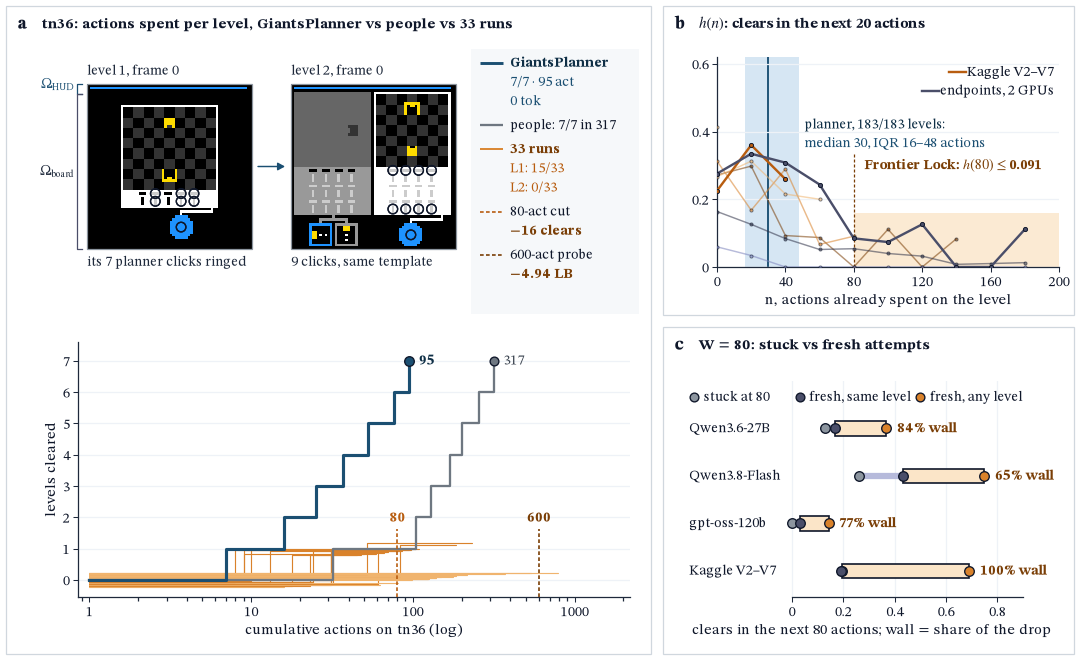

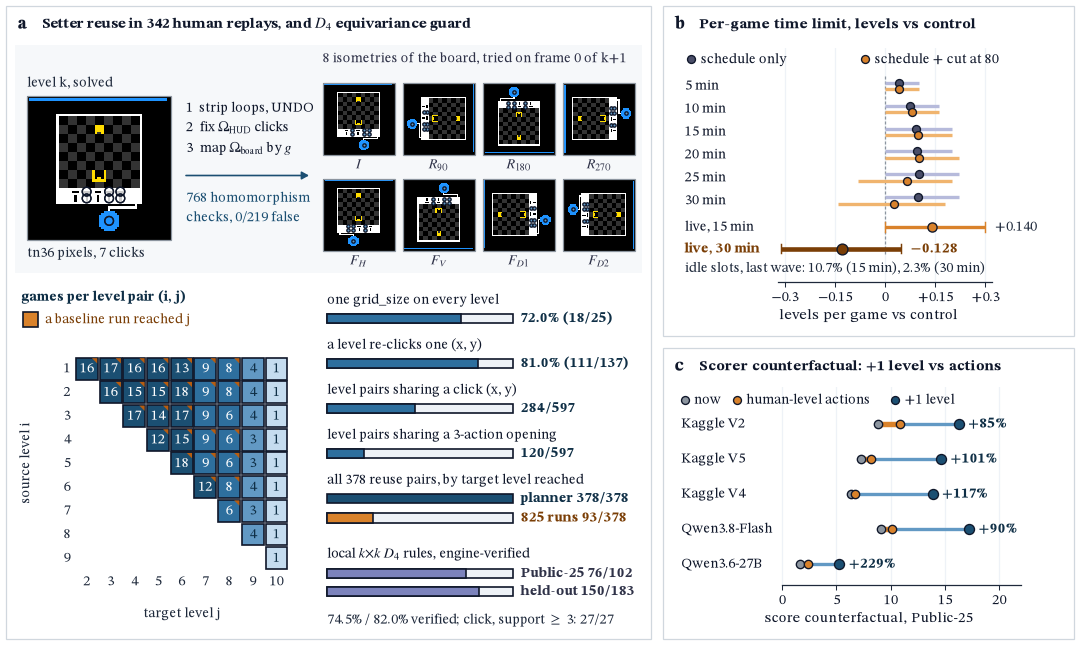

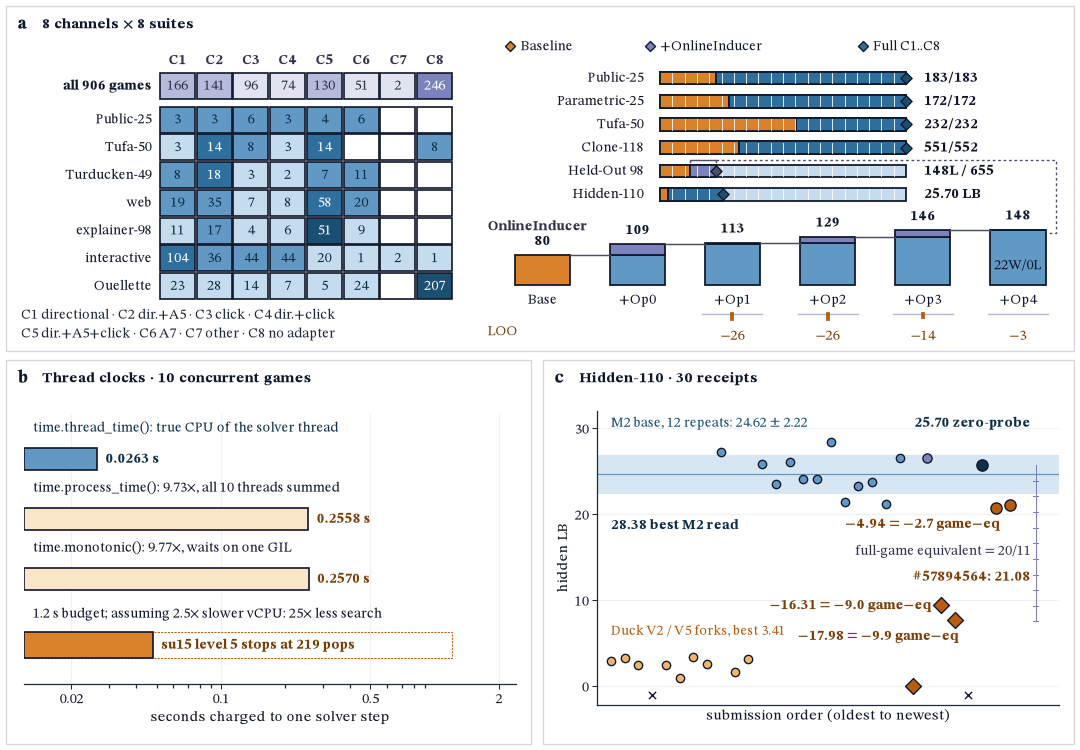

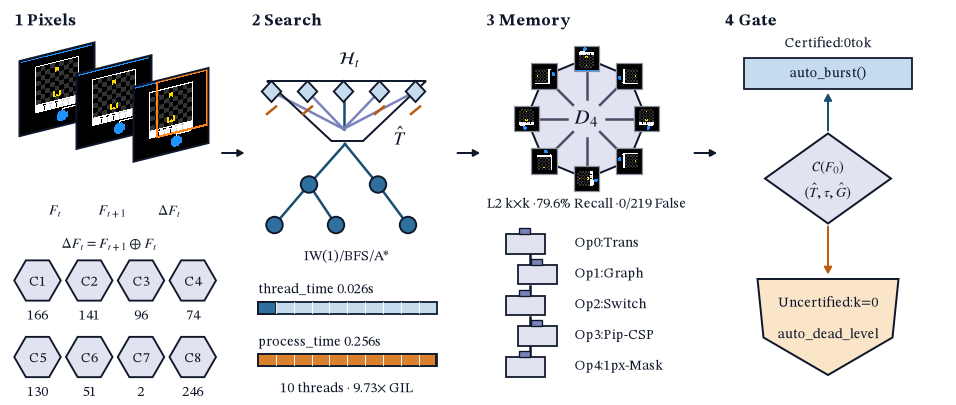

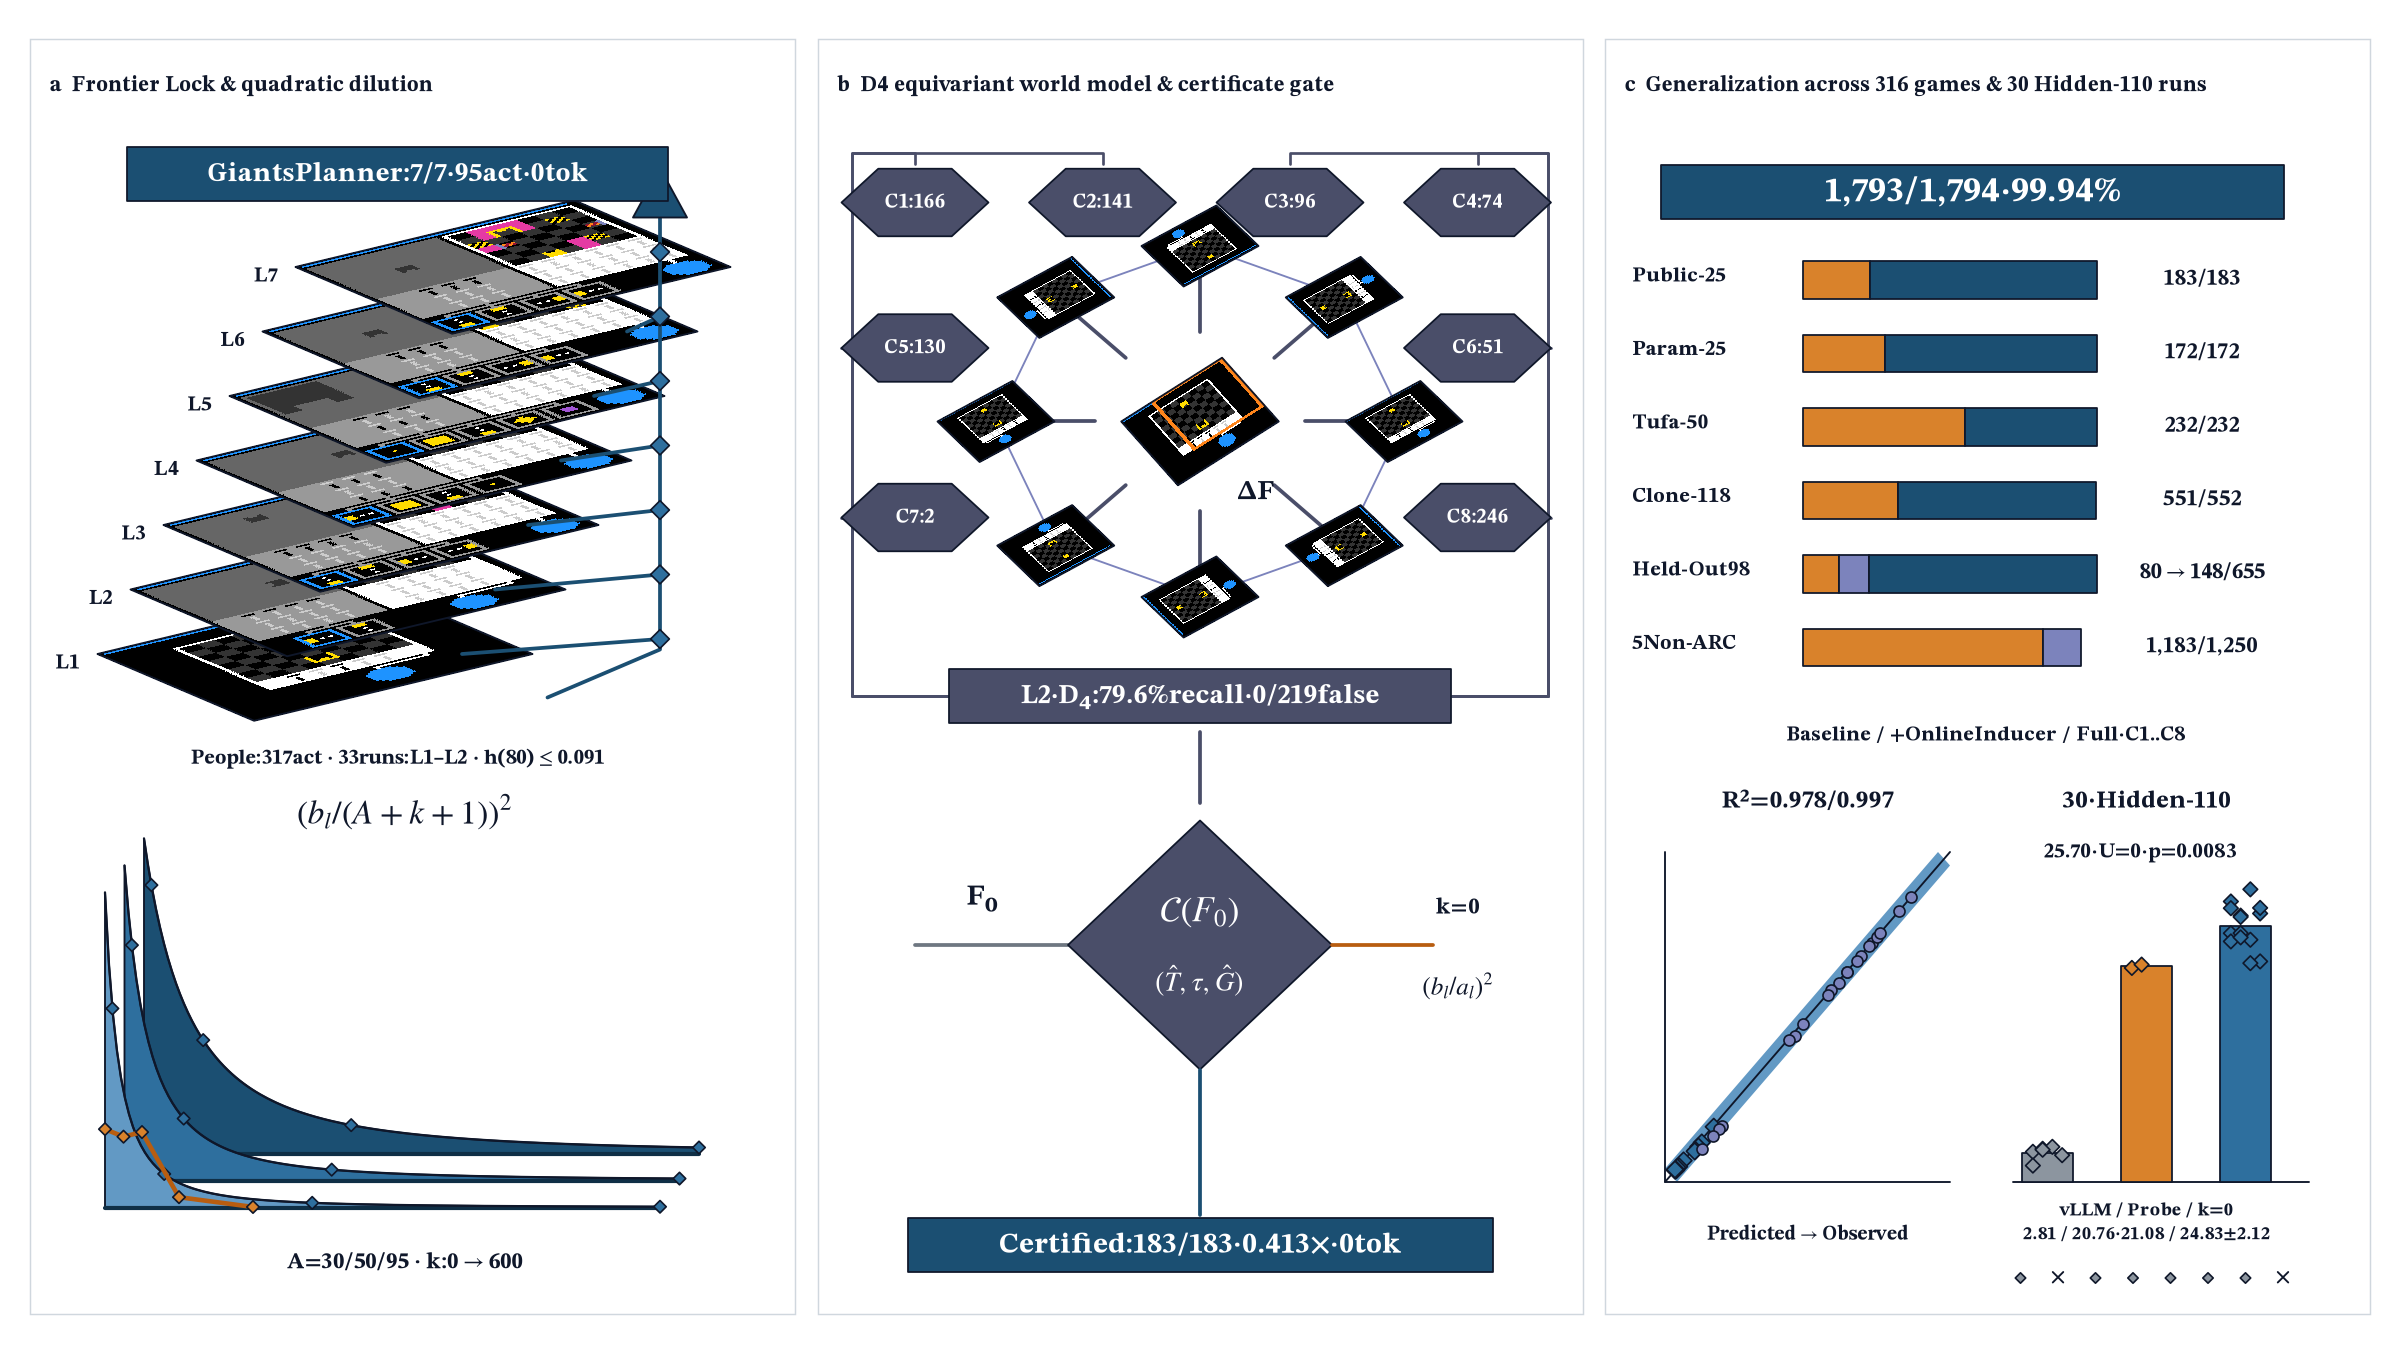

In [9]:
palette = install_module('palette',D['modules']['palette'])
figcheck = install_module('figcheck',D['modules']['figcheck'])
common = install_module('common',D['modules']['common'])
common.__dict__.update(np=np, ROOT=Path.cwd(), OUT=Path.cwd(), load=lambda name:D['traces'][name])
figures = install_module('generate_xray_figures',D['modules']['figures'])
cover = install_module('generate_cover', D['cover']['source'])
cover.COVER_INPUT_NAMES = D['cover']['names']
cover.COVER_INPUTS = D['cover']['records']
cover.COVER_INPUT_HASHES = D['cover']['hashes']
figures.FIG = Path.cwd() / 'frontier_lock_figures'
figures.FIG.mkdir(exist_ok=True)
font_path = figures.FIG / 'STIXTwoText-Regular.ttf'
font_path.write_bytes(base64.b64decode(D['figure_font']))
(figures.FIG / 'FONT-NOTICE.txt').write_text(D['figure_font_notice'])
from matplotlib import font_manager
font_manager.fontManager.addfont(str(font_path))
bold_font_path = figures.FIG / 'STIXTwoText-Bold.ttf'
bold_font_path.write_bytes(base64.b64decode(D['figure_font_bold']))
font_manager.fontManager.addfont(str(bold_font_path))
figures.J = lambda name: D['xray'] if name=='x0_specimens' else D['analysis'][name]
figures.heldout_sources = lambda: D['heldout_ladder']
figures.l2_sources = lambda: D['l2_rules']
figures.setup()
import platform
from matplotlib import ft2font
from PIL import Image, __version__ as pillow_version
render_environment = {'system': platform.system(), 'machine': platform.machine(),
                      'matplotlib': matplotlib.__version__, 'freetype': ft2font.__freetype_version__,
                      'pillow': pillow_version}
figure_inputs = lambda: hashlib.sha256(pickle.dumps(
    [D[k] for k in ('xray','analysis','heldout_ladder','l2_rules','cover')],protocol=5)).hexdigest()
input_sha256 = figure_inputs()
shipped_roots = [p for p in (Path.cwd(),Path.cwd().parent) if (p/'paper/frontier-lock.md').is_file()]
for root in shipped_roots:
    assert {n: hashlib.sha256((root/'paper/figures'/(n+'.png')).read_bytes()).hexdigest()
            for n in D['figure_png_sha256']} == D['figure_png_sha256']
figure_checks = {}
def notebook_save(fig,name,report):
    figures.cel_finish(fig,name)
    hits = figcheck.report(fig,name)
    fig.savefig(figures.FIG / (name+'.pdf'))
    fig.savefig(figures.FIG / (name+'.png'),dpi=300)
    audit = figures.hue_audit(figures.FIG / (name+'.png'))
    with Image.open(figures.FIG / (name+'.png')) as image:
        geometry = {'size':list(image.size),'dpi':list(image.info['dpi'])}
    compare_statistics(geometry, D['figure_geometry'][name], 'figure_geometry/' + name)
    assert not hits and audit['green_px']==0, (name,hits,audit)
    report[name] = {'figcheck_hits':len(hits),**audit}
    plt.show()
figures.save = notebook_save
for draw_figure in (figures.figure_one,figures.figure_two,figures.figure_three,figures.figure_architecture,figures.figure_cover):
    draw_figure(D['xray'],figure_checks)
# The overview uses its own exact 210-dpi renderer and the same mechanical audits.
plt.show()
assert len(figure_checks)==5
rendered_sha256 = {n: hashlib.sha256((figures.FIG / (n+'.png')).read_bytes()).hexdigest()
                   for n in figure_checks}
if render_environment == D['figure_render_environment']:
    assert rendered_sha256 == D['figure_png_sha256']
assert figure_inputs() == input_sha256
checks['figures'] = figure_checks
checks['figure_reproduction'] = {'environment':render_environment,
    'source_environment':D['figure_render_environment'],
    'byte_identical':rendered_sha256 == D['figure_png_sha256'],
    'same_render_environment':render_environment == D['figure_render_environment'],
    'shipped_figures_checked':len(shipped_roots), 'statistical_inputs_unchanged':True,
    'input_sha256':input_sha256, 'rendered_sha256':rendered_sha256}

## 9. Frozen OnlineInducer operator ladder and L2 local D₄ rules
The 98 held-out games carry one row each: solvable levels, then levels cleared by the zero-prior planner,
by +Op2, by +Op3, and by the 1px drift refit (Op4) run on Op1+Op2. +Op4 Full takes the better of +Op3 and
Op4 on every game. Level sums, wins and the paired game bootstrap (10,000 draws, seed 0) are recomputed here.
The L2 rows count local k×k D₄ rules replayed one step in the engine.

In [10]:
lad = figures.component_ladder(D['heldout_ladder'])
R, T = lad['rungs'], lad['vs_zero_prior']
expected = {'Zero-Prior':[80,4],'+Op0 Trans':[109,6],'+Op1 Graph':[113,7],'+Op2 Click+Rew':[129,9],
            '+Op3 Clue CSP':[146,11],'Op4 alone':[132,9],'+Op4 Full':[148,11]}
assert {k:R[k] for k in expected} == expected, R
print('Held-out 98, 655 solvable levels, frozen OnlineInducer operator by operator')
print('  Pre-exp: 72/655 levels, 2 WIN (frozen pre-exposure snapshot, Table K1)')
for k in ('Zero-Prior','+Op0 Trans','+Op1 Graph','+Op2 Click+Rew','+Op3 Clue CSP','+Op4 Full'):
    print(f'  {k}: {R[k][0]}/655 levels, {R[k][1]} WIN')
paired = {'+Op2 Click+Rew':[49,24,79,17,0],'+Op3 Clue CSP':[66,36,101,21,0],'Op4 alone':[52,27,82,19,0],
          '+Op4 Full':[68,38,103,22,0],'+Op3 over Op2':[17,1,40,4,0]}
assert {k:T[k] for k in paired} == paired, T
for k,(d,lo,hi,w,l) in T.items():
    ref = 'Op1+Op2' if k == '+Op3 over Op2' else 'Zero-Prior'
    print(f'  {k} vs {ref}: {d:+d} levels [{lo:+d}, {hi:+d}], {w}W/{l}L')
w, l = T['+Op4 Full'][3:]
assert (l, w + l) == (0, 22)
C = D['heldout_ladder']['certificates']
aborted = C['false_goal'] + C['false_unlock']
assert (aborted, C['issued']) == (36, 361) and C['goal'] + C['unlock'] + C['optimistic'] == C['issued']
assert C['probes_planned'] == 0
print(f"Graph-operator run before the single frozen file: {aborted}/{C['issued']} certificates aborted at L_mon = 1; "
      f"{l}/{w+l} game regressions (single-file readings: Section 10, T3)")
assert lad['public25'] == [120,13,0,0]
print('Public-25 under +Op3: 120/183 levels, 13 WIN, 0W/0L vs Zero-Prior')
L2 = D['l2_rules']
rows = [('Public-25 reuse pairs, engine diff', L2['public25_reuse'], (76,102)),
        ('Public-25 reuse pairs, inside the rule window', L2['public25_reuse_local'], (86,102)),
        ('Public-25 click-reuse pairs', L2['public25_click'], (69,74)),
        ('Public-25 click-reuse pairs, support >= 3', L2['public25_click_support3'], (27,27)),
        ('Held-out 49 pairs, engine diff', L2['heldout'], (150,183)),
        ('Held-out 49 pairs, inside the rule window', L2['heldout_local'], (163,183))]
for name, r, exp in rows:
    assert (r['rules_verified'], r['rules_fired']) == exp, (name, r)
    print(f"L2 {name}: {r['rules_verified']}/{r['rules_fired']} = {100*r['rules_verified']/r['rules_fired']:.1f}% "
          f"rules verified on {r['pairs_with_verified_rule']}/{r['pairs']} pairs")
pr, ho = L2['public25_reuse'], L2['heldout']
assert (pr['pairs_with_verified_rule'], pr['pairs'], pr['verified_under_non_identity_isometry']) == (50, 378, 31)
assert (ho['pairs_with_verified_rule'], ho['pairs'], ho['verified_under_non_identity_isometry']) == (103, 651, 27)
assert L2['public25_click_support3']['rules_wrong'] == 0
print(f"Non-identity D4 isometries: {pr['verified_under_non_identity_isometry']}/{pr['rules_verified']} (Public-25), "
      f"{ho['verified_under_non_identity_isometry']}/{ho['rules_verified']} (held-out)")
checks['operator_ladder'] = {'rungs': {k: R[k] for k in expected}, 'vs_zero_prior': T,
                             'eta_cert': [aborted, C['issued']], 'eta_game': [l, w + l]}
checks['l2_local_d4'] = {name: [r['rules_verified'], r['rules_fired']] for name, r, _ in rows}

Held-out 98, 655 solvable levels, frozen OnlineInducer operator by operator
  Pre-exp: 72/655 levels, 2 WIN (frozen pre-exposure snapshot, Table K1)
  Zero-Prior: 80/655 levels, 4 WIN
  +Op0 Trans: 109/655 levels, 6 WIN
  +Op1 Graph: 113/655 levels, 7 WIN
  +Op2 Click+Rew: 129/655 levels, 9 WIN
  +Op3 Clue CSP: 146/655 levels, 11 WIN
  +Op4 Full: 148/655 levels, 11 WIN
  +Op2 Click+Rew vs Zero-Prior: +49 levels [+24, +79], 17W/0L
  +Op3 Clue CSP vs Zero-Prior: +66 levels [+36, +101], 21W/0L
  Op4 alone vs Zero-Prior: +52 levels [+27, +82], 19W/0L
  +Op4 Full vs Zero-Prior: +68 levels [+38, +103], 22W/0L
  +Op3 over Op2 vs Op1+Op2: +17 levels [+1, +40], 4W/0L
Graph-operator run before the single frozen file: 36/361 certificates aborted at L_mon = 1; 0/22 game regressions (single-file readings: Section 10, T3)
Public-25 under +Op3: 120/183 levels, 13 WIN, 0W/0L vs Zero-Prior
L2 Public-25 reuse pairs, engine diff: 76/102 = 74.5% rules verified on 50/378 pairs
L2 Public-25 reuse pairs, ins

## 10. Single frozen OnlineInducer file: Bare-Prior, cumulative and leave-one-out, certificates, Scorecard G
One plugin file (SHA-256 recorded at preregistration) runs every arm below with operators switched on or off.
Budget per game: 1,200 actions, 20 s thread CPU, seed 0. Each cell recomputes its readings from one row per game
and checks them against the stored run summary.

**T1 · Bare-Prior.** All eight planner channels off; the inducer alone on the 98 held-out games and the
preregistered Virgin-120 suite.

In [11]:
H = D['heldout_ladder']
A9, P9, CI9 = lad['v9_arms'], lad['v9_paired'], lad['v9_stored_ci']
b = P9['bare_v9']
assert A9['bare'] == [74, 1] and A9['bare_v9'] == [109, 6] and [b[0], b[3], b[4]] == [35, 11, 5]
print(f"Held-out 98, Bare-Prior: {A9['bare'][0]}/655 levels ({A9['bare'][1]} WIN) -> +OnlineInducer "
      f"{A9['bare_v9'][0]}/655 ({A9['bare_v9'][1]} WIN): {b[0]:+d}L, recomputed 95% CI [{b[1]:+d}, {b[2]:+d}] "
      f"(stored [{CI9['bare_v9'][0]:+d}, {CI9['bare_v9'][1]:+d}]), {b[3]}W/{b[4]}L")
V = H['virgin']
col = {c: i for i, c in enumerate(V['columns'], 1)}
vper = {c: [r[col[c]] for r in V['per_game']] for c in V['columns']}
varm = {c: [sum(vper[c]), sum(x == t for x, t in zip(vper[c], vper['total']))] for c in V['stored']}
compare_statistics(varm, V['stored'], 'virgin_pairing')
d = [y - x for x, y in zip(vper['vbare'], vper['vbare_v9'])]
vb = [sum(d), sum(x > 0 for x in d), sum(x < 0 for x in d)]
assert len(d) == 120 and vb == [7, 5, 2]
print(f"Virgin-120, Bare-Prior: {varm['vbare'][0]} levels ({varm['vbare'][1]} WIN) -> +OnlineInducer "
      f"{varm['vbare_v9'][0]} ({varm['vbare_v9'][1]} WIN): {vb[0]:+d}L, {vb[1]}W/{vb[2]}L")
checks['T1_bare_prior'] = {'held_out_98': [A9['bare'], A9['bare_v9'], b], 'virgin_120': [varm['vbare'], varm['vbare_v9'], vb]}

Held-out 98, Bare-Prior: 74/655 levels (1 WIN) -> +OnlineInducer 109/655 (6 WIN): +35L, recomputed 95% CI [+8, +66] (stored [+8, +66]), 11W/5L
Virgin-120, Bare-Prior: 92 levels (5 WIN) -> +OnlineInducer 99 (6 WIN): +7L, 5W/2L


**T2 · Cumulative ladder and leave-one-out.** The cumulative rungs on the 98 held-out games, the frozen +Op4
default (weak-body refit off) at 148 levels, and the full operator configuration with each operator removed in turn.

In [12]:
R0 = H['v9b_r0']
keys = [r[0] for r in H['per_game']]
zero = {r[0]: r[2] for r in H['per_game']}
r0 = [sum(R0[k][0] for k in keys), sum(R0[k][1] for k in keys)]
d = [R0[k][0] - zero[k] for k in keys]
r0p = [sum(d), *figures.paired_boot(d), sum(x > 0 for x in d), sum(x < 0 for x in d)]
assert r0 == [148, 11] and r0p[0] == 68 and r0p[4] == 0 and H['v9b_r0_public25'] == [120, 13]
for k in ('Zero-Prior', '+Op0 Trans', '+Op1 Graph', '+Op2 Click+Rew', '+Op3 Clue CSP'):
    print(f'  {k}: {R[k][0]}/655 levels, {R[k][1]} WIN')
print(f"  +Op4 default (refit off): {r0[0]}/655 levels, {r0[1]} WIN; vs Zero-Prior {r0p[0]:+d}L "
      f"[{r0p[1]:+d}, {r0p[2]:+d}], {r0p[3]}W/{r0p[4]}L; Public-25 {H['v9b_r0_public25'][0]}/183, {H['v9b_r0_public25'][1]} WIN")
full = A9['v9']
assert full == [146, 11]
loo = {'Op1': 'loo1', 'Op2': 'loo2', 'Op3': 'loo3', 'Op4': 'L3'}
expect = {'Op1': [26, 14, 0], 'Op2': [26, 5, 0], 'Op3': [14, 2, 0], 'Op4': [3, 2, 0]}
for op, c in loo.items():
    p = P9[c]
    assert [p[0], p[3], p[4]] == expect[op], (op, p)
    print(f"  OnlineInducer {full[0]}L without {op}: {A9[c][0]}L ({A9[c][1]} WIN), drop {-p[0]:+d}L "
          f"[{-p[2]:+d}, {-p[1]:+d}], {p[3]}W/{p[4]}L for the full file")
checks['T2_ladder_loo'] = {'v9b_r0': [r0, r0p], 'v9_full': full, 'loo': {op: [A9[c], P9[c]] for op, c in loo.items()}}

  Zero-Prior: 80/655 levels, 4 WIN
  +Op0 Trans: 109/655 levels, 6 WIN
  +Op1 Graph: 113/655 levels, 7 WIN
  +Op2 Click+Rew: 129/655 levels, 9 WIN
  +Op3 Clue CSP: 146/655 levels, 11 WIN
  +Op4 default (refit off): 148/655 levels, 11 WIN; vs Zero-Prior +68L [+38, +103], 22W/0L; Public-25 120/183, 13 WIN
  OnlineInducer 146L without Op1: 120L (8 WIN), drop -26L [-42, -13], 14W/0L for the full file
  OnlineInducer 146L without Op2: 120L (9 WIN), drop -26L [-52, -4], 5W/0L for the full file
  OnlineInducer 146L without Op3: 132L (9 WIN), drop -14L [-36, +0], 2W/0L for the full file
  OnlineInducer 146L without Op4: 143L (11 WIN), drop -3L [-8, +0], 2W/0L for the full file


**T3 · Certificate abort rate.** A certificate is checked one step after it fires ($L_{mon}=1$); a mismatch
aborts it. $\hat{\eta}_{cert}$ counts aborted certificates, $\hat{\eta}_{game}$ counts activated games that end
with fewer levels than the planner alone.

In [13]:
CE = H['v9_certificates']
rows3 = {}
for name, c in CE.items():
    assert sum(c['abort_position'].values()) == c['N_cert_aborted'] and c['wasted_steps_per_abort_bound'] == 1
    assert c['graph']['issued'] + c['clue']['issued'] == c['N_cert_issued']
    rows3[name] = [c['N_cert_aborted'], c['N_cert_issued']]
    line = f"  {name}: eta_cert = {c['N_cert_aborted']}/{c['N_cert_issued']} = {100*c['N_cert_aborted']/c['N_cert_issued']:.1f}%"
    if 'eta_game' in c:
        g = c['eta_game']
        line += f"; eta_game = {g['net_loss_games']}/{g['activated_games']} ({g['net_win_games']} games up)"
        rows3[name] += [g['net_loss_games'], g['activated_games']]
    print(line)
assert rows3['Held-out 98'] == [44, 380, 0, 89] and rows3['Virgin (bare floor)'] == [3, 40]
assert rows3['Virgin'] == [35, 102, 9, 103]
checks['T3_eta'] = rows3

  Held-out 98: eta_cert = 44/380 = 11.6%; eta_game = 0/89 (21 games up)
  Held-out 98 (bare floor): eta_cert = 31/408 = 7.6%
  Virgin: eta_cert = 35/102 = 34.3%; eta_game = 9/103 (8 games up)
  Virgin (bare floor): eta_cert = 3/40 = 7.5%


**T4 · Official Scorecard G.** Level score $\min(115, 100(b_l/a_l)^2)$, weight $l$, game score capped by
cleared weight. Public-25 uses the official human baseline actions; the held-out and Virgin games use the fewest
actions any run of this study spent on that level. Mean G per arm and the paired two-sided Wilcoxon signed-rank
test (zeros dropped) are recomputed from one G per game.

In [14]:
from scipy import stats
SG, SC = H['v9_scorecard_games']['sets'], H['v9_scorecard']
t4 = {}
for g in ('Public-25', 'Held-out 98', 'Virgin'):
    G = SG[g]['G']
    for a, v in G.items():
        assert round(sum(v) / len(v), 3) == SC[g]['arms'][a]['mean_G'], (g, a)
    for name, s in SC[g]['paired'].items():
        x, y = name.split(' -> ')
        diff = [q - p for p, q in zip(G[x], G[y])]
        pv = float(stats.wilcoxon(diff, zero_method='wilcox', alternative='two-sided').pvalue) if any(diff) else 1.0
        assert math.isclose(pv, s['wilcoxon_p'], rel_tol=1e-9), (g, name, pv, s['wilcoxon_p'])
        up, down = sum(z > 1e-9 for z in diff), sum(z < -1e-9 for z in diff)
        assert (up, down) == (s['games_up'], s['games_down'])
        t4[f'{g}: {name}'] = [round(sum(G[x]) / len(diff), 2), round(sum(G[y]) / len(diff), 2), pv, up, down]
        print(f"  {g}, {name}: G {t4[f'{g}: {name}'][0]:.2f} -> {t4[f'{g}: {name}'][1]:.2f}, Wilcoxon p = {pv:.3g}, "
              f"{up} games up / {down} down")
compare_statistics(t4['Public-25: ungated_open_224 -> gated_general'][:2], [15.21, 58.43], 'T4/Public-25')
compare_statistics(t4['Held-out 98: ungated_open_224 -> gated_v9'][:2], [1.99, 15.42], 'T4/Held-out 98')
compare_statistics(t4['Virgin: ungated_open_224 -> gated_general'][:2], [4.92, 10.6], 'T4/Virgin')
checks['T4_scorecard_G'] = t4

  Public-25, gated_general -> gated_v9: G 58.43 -> 58.43, Wilcoxon p = 1, 1 games up / 2 down
  Public-25, ungated_open_224 -> gated_general: G 15.21 -> 58.43, Wilcoxon p = 5.96e-08, 25 games up / 0 down
  Public-25, ungated_open_600 -> gated_general: G 15.15 -> 58.43, Wilcoxon p = 5.96e-08, 25 games up / 0 down
  Public-25, ungated_open_224 -> gated_v9: G 15.21 -> 58.43, Wilcoxon p = 1.19e-07, 24 games up / 1 down
  Public-25, ungated_open_600 -> gated_v9: G 15.15 -> 58.43, Wilcoxon p = 1.19e-07, 24 games up / 1 down
  Public-25, bare -> bare_v9: G 0.07 -> 0.29, Wilcoxon p = 0.593, 2 games up / 1 down
  Held-out 98, gated_general -> gated_v9: G 5.84 -> 15.42, Wilcoxon p = 0.000107, 33 games up / 13 down
  Held-out 98, ungated_open_224 -> gated_general: G 1.99 -> 5.84, Wilcoxon p = 0.000463, 42 games up / 11 down
  Held-out 98, ungated_open_600 -> gated_general: G 3.43 -> 5.84, Wilcoxon p = 0.0172, 38 games up / 18 down
  Held-out 98, ungated_open_224 -> gated_v9: G 1.99 -> 15.42, Wilc

## 11. Five-seed paired readout on unseen Virgin-116 and pooled Virgin-236
The frozen OnlineInducer file (one SHA-256, preregistered before any policy acted on Virgin-116) runs on the
116-game Virgin-116 suite (594 levels) and on Virgin-236 (Virgin-120 plus Virgin-116, 1,404 levels), seeds 0 to 4,
1,200 actions per game. Every number below is recomputed from one row per game, seed and arm: level sums, wins,
the per-game five-seed mean difference, its paired game bootstrap (10,000 draws, seed 0), the two-sided Wilcoxon
signed-rank test, and Scorecard G with the fewest actions any run spent on each level as baseline. Each reading
is then checked against the stored run summary.

In [15]:
import random
VM = D['virgin_multiseed']
VR, VS = VM['rows'], VM['stored']
def boot(diff, n=10000, seed=0, mean=False):
    rng = random.Random(seed); m = len(diff)
    b = sorted(sum(diff[rng.randrange(m)] for _ in range(m)) / (m if mean else 1) for _ in range(n))
    return [round(b[int(0.025 * n) - 1], 3), round(b[int(0.975 * n) - 1], 3)]
def wilcoxon(diff):
    if not any(abs(x) > 1e-12 for x in diff):
        return 1.0
    return float(stats.wilcoxon(diff, zero_method='wilcox', alternative='two-sided').pvalue)
best = defaultdict(dict)
for arm in VR.values():
    for k, (lc, M, win, la) in arm.items():
        for l, a in enumerate(la, 1):
            if a:
                best[k][l] = min(best[k].get(l, 10 ** 9), a)
def scoreG(k, row):
    lc, M, win, la = row
    if not M:
        return 0.0
    W = M * (M + 1) / 2
    s = [min(115.0, 100.0 * (best[k][l] / la[l - 1]) ** 2) if l <= lc and la[l - 1] else 0.0 for l in range(1, M + 1)]
    return min(sum(l * x for l, x in enumerate(s, 1)) / W, 100.0 * sum(l for l, x in enumerate(s, 1) if x > 0) / W)
keys = sorted({k for arm in VR.values() for k in arm})
suite = {'Virgin-116': [k for k in keys if k.startswith('virgin116__')]}
suite['Virgin-236'] = [k for k in keys if k.startswith('virgin__')] + suite['Virgin-116']
assert [len(suite[g]) for g in suite] == [116, 236]
levels_total = {g: sum(VR['bare'][k][1] for k in ks) for g, ks in suite.items()}
assert levels_total == {'Virgin-116': 594, 'Virgin-236': 1404}
seeds_of = lambda t: [VR[t]] + [VR[f'{t}_s{s}'] for s in (1, 2, 3, 4)]
NAME = {'bare': 'Bare-Prior', 'bare_v10b': 'Bare-Prior + OnlineInducer', 'gen': 'general',
        'v10b': 'general + OnlineInducer', 'open224': 'open_224'}
ms = {}
for g, ks in suite.items():
    for a, b in (('bare', 'bare_v10b'), ('gen', 'v10b')):
        A, B = seeds_of(a), seeds_of(b)
        per = [sum(B[s][k][0] - A[s][k][0] for s in range(5)) / 5 for k in ks]
        gper = [sum(scoreG(k, B[s][k]) - scoreG(k, A[s][k]) for s in range(5)) / 5 for k in ks]
        r = dict(mean_levels_a=round(sum(A[s][k][0] for s in range(5) for k in ks) / 5, 2),
                 mean_levels_b=round(sum(B[s][k][0] for s in range(5) for k in ks) / 5, 2),
                 mean_wins_a=round(sum(A[s][k][2] for s in range(5) for k in ks) / 5, 2),
                 mean_wins_b=round(sum(B[s][k][2] for s in range(5) for k in ks) / 5, 2),
                 mean_delta_levels_per_seed=round(sum(per), 3), ci95=boot(per), wilcoxon_p=wilcoxon(per),
                 games_up=sum(x > 0 for x in per), games_down=sum(x < 0 for x in per),
                 mean_G_a=round(sum(scoreG(k, A[s][k]) for s in range(5) for k in ks) / 5 / len(ks), 3),
                 mean_G_b=round(sum(scoreG(k, B[s][k]) for s in range(5) for k in ks) / 5 / len(ks), 3),
                 delta_G=round(sum(gper) / len(ks), 3), delta_G_ci95=boot(gper, mean=True), delta_G_wilcoxon_p=wilcoxon(gper))
        stored = VS['multiseed'][f'{b} - {a} | {g}']
        for x, v in r.items():
            compare_statistics(v, stored[x], f'multiseed/{g}/{a}/{b}/{x}')
        ms[f'{g}: {NAME[a]} -> {NAME[b]}'] = r
        print(f"{g}, 5 seeds, {NAME[a]} -> {NAME[b]}: {r['mean_levels_a']:.1f}L ({r['mean_wins_a']:.1f} WIN, G={r['mean_G_a']:.2f}) "
              f"-> {r['mean_levels_b']:.1f}L ({r['mean_wins_b']:.1f} WIN, G={r['mean_G_b']:.2f}); "
              f"{r['mean_delta_levels_per_seed']:+.1f}L/seed [{r['ci95'][0]:+.1f}, {r['ci95'][1]:+.1f}], "
              f"{r['games_up']} games up / {r['games_down']} down, Wilcoxon p = {r['wilcoxon_p']:.2g}; "
              f"G {r['delta_G']:+.2f} [{r['delta_G_ci95'][0]:+.2f}, {r['delta_G_ci95'][1]:+.2f}], p = {r['delta_G_wilcoxon_p']:.2g}")
u = ms['Virgin-116: Bare-Prior -> Bare-Prior + OnlineInducer']
compare_statistics((u['mean_levels_a'], u['mean_levels_b'], u['mean_delta_levels_per_seed'], u['ci95']), (141.8, 152.2, 10.4, [2.0, 21.4]), 'Virgin-116/levels')
compare_statistics((u['mean_wins_a'], u['mean_wins_b'], u['games_up'], u['games_down'], round(u['wilcoxon_p'], 3)), (12.6, 16.2, 25, 9, 0.017), 'Virgin-116/wins')
compare_statistics((round(u['mean_G_a'], 2), round(u['mean_G_b'], 2), round(u['delta_G'], 2)), (5.85, 9.52, 3.67), 'Virgin-116/G')
compare_statistics([round(x, 2) for x in u['delta_G_ci95']], [2.11, 5.58], 'Virgin-116/G_ci95')
assert f"{u['delta_G_wilcoxon_p']:.1e}" == '1.1e-05'
p = ms['Virgin-236: Bare-Prior -> Bare-Prior + OnlineInducer']
compare_statistics((p['mean_levels_a'], p['mean_levels_b'], p['mean_delta_levels_per_seed'], p['ci95']), (235.8, 247.4, 11.6, [0.4, 24.2]), 'Virgin-236/levels')
compare_statistics((p['mean_wins_a'], p['mean_wins_b'], p['games_up'], p['games_down'], round(p['wilcoxon_p'], 3)), (15.6, 19.8, 44, 25, 0.029), 'Virgin-236/wins')
compare_statistics((round(p['mean_G_a'], 2), round(p['mean_G_b'], 2), round(p['delta_G'], 2)), (4.05, 6.09, 2.04), 'Virgin-236/G')
compare_statistics([round(x, 2) for x in p['delta_G_ci95']], [1.09, 3.12], 'Virgin-236/G_ci95')
assert f"{p['delta_G_wilcoxon_p']:.1e}" == '3.0e-04'
assert all(r['ci95'][0] > 0 and r['delta_G_ci95'][0] > 0 for r in (u, p))

# Seed 0: general + OnlineInducer against the ungated 224-step open loop on Virgin-116, and the pooled Virgin-236 view.
s0 = {}
for g, ks in suite.items():
    for t in ('bare', 'bare_v10b', 'gen', 'v10b', 'open224'):
        if all(k in VR[t] for k in ks):
            s0[(g, t)] = [sum(VR[t][k][0] for k in ks), sum(VR[t][k][2] for k in ks), [scoreG(k, VR[t][k]) for k in ks]]
            st = VS['main_seed0'][g][t]
            assert s0[(g, t)][:2] == [st['levels'], st['wins']], (g, t)
            assert round(sum(s0[(g, t)][2]) / len(ks), 3) == VS['scorecard_seed0'][g]['mean_G'][t], (g, t)
ks = suite['Virgin-116']
oi, op = s0[('Virgin-116', 'v10b')], s0[('Virgin-116', 'open224')]
diff = [y - x for x, y in zip(op[2], oi[2])]
gate = dict(levels=[op[0], oi[0]], wins=[op[1], oi[1]], G=[round(sum(op[2]) / 116, 3), round(sum(oi[2]) / 116, 3)],
            delta=round(sum(diff) / 116, 3), ci95=boot(diff, mean=True), wilcoxon_p=wilcoxon(diff),
            up=sum(x > 1e-9 for x in diff), down=sum(x < -1e-9 for x in diff))
sp = VS['scorecard_seed0']['Virgin-116']['paired']['open224 to v10b']
compare_statistics((gate['delta'], gate['ci95'], gate['up'], gate['down']), (sp['delta'], sp['ci95'], sp['up'], sp['down']), 'Virgin-116/gate')
assert math.isclose(gate['wilcoxon_p'], sp['wilcoxon_p'], rel_tol=1e-9)
assert gate['levels'] == [237, 243] and gate['wins'] == [35, 40]
compare_statistics([round(x, 2) for x in gate['G']], [9.8, 31.35], 'Virgin-116/gate/G')
assert f"{gate['wilcoxon_p']:.1e}" == '1.1e-09' and (gate['up'], gate['down']) == (65, 9)
print(f"Virgin-116, seed 0: {NAME['open224']} {gate['levels'][0]}L ({gate['wins'][0]} WIN, G={gate['G'][0]:.2f}) -> "
      f"{NAME['v10b']} {gate['levels'][1]}L ({gate['wins'][1]} WIN, G={gate['G'][1]:.2f}); G {gate['delta']:+.2f} "
      f"[{gate['ci95'][0]:+.2f}, {gate['ci95'][1]:+.2f}], Wilcoxon p = {gate['wilcoxon_p']:.2g}, {gate['up']} games up / {gate['down']} down")
full = s0[('Virgin-236', 'v10b')]
g236 = ms['Virgin-236: general -> general + OnlineInducer']
assert full[:2] == [383, 49] and round(sum(full[2]) / 236, 3) == 19.778 and round(g236['mean_G_b'], 2) == 19.44
# Virgin-120 has no open_224 row in this five-seed run; its open-loop rows come from the section 10 runs.
SGv = H['v9_scorecard_games']['sets']['Virgin']
assert SGv['games'] == suite['Virgin-236'][:120]
v120_open = {c: [sum(vper[c]), sum(x == t for x, t in zip(vper[c], vper['total']))] for c in ('vopen224', 'vopen600')}
pool = {c: round((sum(SGv['G'][a]) + sum(op[2])) / 236, 3) for c, a in (('vopen224', 'ungated_open_224'), ('vopen600', 'ungated_open_600'))}
assert v120_open['vopen224'] == [122, 8]
compare_statistics(pool, {'vopen224': 7.318, 'vopen600': 7.358}, 'Virgin-236/pool')
print(f"Virgin-236, seed 0: {NAME['v10b']} {full[0]}L ({full[1]} WIN, G={sum(full[2]) / 236:.2f}; five-seed mean G={g236['mean_G_b']:.2f}); "
      f"pooled open loop {op[0] + v120_open['vopen224'][0]}L ({op[1] + v120_open['vopen224'][1]} WIN), "
      f"G={pool['vopen224']:.2f} with open_224 on both halves, G={pool['vopen600']:.2f} with open_600 on Virgin-120")
checks['virgin_multiseed'] = {'five_seed': ms, 'virgin116_gate_seed0': gate,
                              'virgin236_general_oi_seed0': [full[0], full[1], round(sum(full[2]) / 236, 3)],
                              'virgin236_open_loop_pooled_G': pool}

Virgin-116, 5 seeds, Bare-Prior -> Bare-Prior + OnlineInducer: 141.8L (12.6 WIN, G=5.85) -> 152.2L (16.2 WIN, G=9.52); +10.4L/seed [+2.0, +21.4], 25 games up / 9 down, Wilcoxon p = 0.017; G +3.67 [+2.11, +5.58], p = 1.1e-05
Virgin-116, 5 seeds, general -> general + OnlineInducer: 239.0L (38.0 WIN, G=29.82) -> 240.6L (39.2 WIN, G=30.77); +1.6L/seed [-2.6, +7.0], 2 games up / 2 down, Wilcoxon p = 0.58; G +0.96 [-0.23, +2.30], p = 0.37
Virgin-236, 5 seeds, Bare-Prior -> Bare-Prior + OnlineInducer: 235.8L (15.6 WIN, G=4.05) -> 247.4L (19.8 WIN, G=6.09); +11.6L/seed [+0.4, +24.2], 44 games up / 25 down, Wilcoxon p = 0.029; G +2.04 [+1.09, +3.12], p = 0.0003
Virgin-236, 5 seeds, general -> general + OnlineInducer: 371.0L (47.0 WIN, G=19.19) -> 379.8L (48.2 WIN, G=19.44); +8.8L/seed [-1.6, +20.8], 10 games up / 7 down, Wilcoxon p = 0.13; G +0.25 [-0.82, +1.25], p = 0.97
Virgin-116, seed 0: open_224 237L (35 WIN, G=9.80) -> general + OnlineInducer 243L (40 WIN, G=31.35); G +21.55 [+14.33, +28.

## 12. Discrete renewal rate: exact forward-difference identity
With survival $S(n)=P(T>n)$, cutoff $c$ and failure-only reset cost $d$, the renewal reward rate is
$R_c=(1-S(c))/\mu_c$ with $\mu_c=\sum_{n<c}S(n)+dS(c)$. Adjacent cutoffs satisfy
$R_{c+1}-R_c=\frac{S(c)}{\mu_{c+1}}\left[h(c+1)(1+dR_c)-R_c\right]$, $h(c+1)=1-S(c+1)/S(c)$.
The identity is checked in exact rational arithmetic on 36 frailty-mixture cases, then on the Kaplan-Meier
survival curves of all 8 baseline datasets for every cutoff 1 to 160 and $d\in\{0,1,3\}$.

In [16]:
RN = VM['renewal']
cases, exact_err = 0, F(0)
for w in ((F(1, 5), F(4, 5)), (F(1, 2), F(1, 2)), (F(9, 10), F(1, 10))):
    p1 = [F(10, 100), F(25, 100), F(15, 100), F(5, 100), F(5, 100)]
    p2 = [F(2, 100), F(3, 100), F(5, 100), F(10, 100), F(20, 100)]
    f = [w[0] * a + w[1] * b for a, b in zip(p1, p2)]
    S = [F(1)]
    for x in f:
        S.append(S[-1] - x)
    for dd in (0, 1, 3):
        for c in range(1, 5):
            mu, mu1 = sum(S[:c]) + dd * S[c], sum(S[:c + 1]) + dd * S[c + 1]
            R, R1 = (1 - S[c]) / mu, (1 - S[c + 1]) / mu1
            rhs = S[c] / mu1 * (f[c] / S[c] * (1 + dd * R) - R)
            exact_err = max(exact_err, abs(R1 - R - rhs))
            cases += 1
assert cases == 36 and exact_err == 0
m = [F(0)] * 13
for t in range(1, 13):
    m[t] = F(1, 2) * (1 + m[t - 1]) + (F(1, 4) * (1 + m[t - 2]) if t >= 2 else 0) + (F(1, 4) * m[t - 3] if t >= 3 else 0)
assert [str(x) for x in m] == RN['finite_horizon_example']
km_err, km_cases, flat = 0.0, 0, 0
for name, runs in D['traces'].items():
    rows = [r for r in attempts(runs) if r[3] or r[2] > 0]
    dur = np.array([r[2] for r in rows]); events = np.array([r[3] for r in rows])
    S, _ = km(dur, events, list(range(0, 162)))
    S = [float(x) for x in S]
    k80 = RN['km_c80'][name]
    assert math.isclose(S[80], k80['S_c'], rel_tol=1e-12) and math.isclose(sum(S[:80]), k80['E_min_T_c'], rel_tol=1e-12)
    assert math.isclose((1 - S[80]) / sum(S[:80]), k80['R_c'], rel_tol=1e-12)
    for dd in (0, 1, 3):
        for c in range(1, 161):
            mu, mu1 = sum(S[:c]) + dd * S[c], sum(S[:c + 1]) + dd * S[c + 1]
            R, R1 = (1 - S[c]) / mu, (1 - S[c + 1]) / mu1
            if S[c] == 0:
                assert R1 == R
                flat += 1
                continue
            rhs = S[c] / mu1 * ((1 - S[c + 1] / S[c]) * (1 + dd * R) - R)
            km_err = max(km_err, abs(R1 - R - rhs))
            km_cases += 1
assert km_err < 1e-12
print(f'Exact rational identity: {cases}/36 cases, max error {exact_err}; finite-horizon recurrence matches 13/13 terms')
print(f'Kaplan-Meier identity: {km_cases} cutoff cases over {len(D["traces"])} datasets, max |error| = {km_err:.2e}; '
      f'{flat} cases with S(c)=0 keep R_c+1 = R_c; R_80 matches the stored hazard audit on 8/8 datasets')
checks['renewal_identity'] = {'exact_cases': cases, 'exact_max_error': str(exact_err), 'km_cases': km_cases,
                              'km_max_error': km_err, 'flat_cases': flat}

Exact rational identity: 36/36 cases, max error 0; finite-horizon recurrence matches 13/13 terms
Kaplan-Meier identity: 3840 cutoff cases over 8 datasets, max |error| = 9.87e-18; 0 cases with S(c)=0 keep R_c+1 = R_c; R_80 matches the stored hazard audit on 8/8 datasets


## 13. Manuscript references
The 40 numbered references of the manuscript are embedded. Numbering is contiguous, entries are distinct, every
reference is cited in the body, and every body citation resolves to an entry.

In [17]:
RF = D['references']
nums = [int(n) for n, _ in RF['entries']]
texts = [t.strip() for _, t in RF['entries']]
assert nums == list(range(1, 41)) and len(set(texts)) == 40
assert RF['cited'] == list(range(1, 41)), sorted(set(range(1, 41)) ^ set(RF['cited']))
print(f"References: {len(nums)} entries [1]..[{nums[-1]}], {len(set(texts))} distinct, "
      f"{len(RF['cited'])}/40 cited in the body, 0 unresolved citations")
checks['references'] = {'entries': len(nums), 'cited': len(RF['cited'])}

References: 40 entries [1]..[40], 40 distinct, 40/40 cited in the body, 0 unresolved citations


In [18]:
from scipy import stats
exec(D['virgin_ladder']['analysis_source'])
latest = recompute_operator_ladder_and_law()
assert latest['passed'] and sum(latest['identity']['files'].values()) == 36165
latest = json.loads(json.dumps(latest, default=float))
stored = D['virgin_ladder']['stored']
compare_statistics(latest['ladder'],stored['ladder'],'ladder')
compare_statistics(latest['dilution_law'],stored['dilution_law'],'dilution_law')
no_clue = latest['ladder']['bare | Virgin-116']['cumulative']['+Op0+Op1+Op2+Op4 (no Op3) vs floor']
compare_statistics((no_clue['delta_levels_per_seed'], no_clue['ci95']), (10.4, [2.2, 21.4]), 'ladder/no_Op3')
assert (no_clue['games_up'], no_clue['games_down']) == (25, 9)
fit = latest['dilution_law']['suite_cell_fit']['out_of_sample_three_suites']['law']
compare_statistics(fit, {'cells': 15, 'MAE': 0.409, 'R2': 0.9781, 'max_abs_err': 1.161}, 'dilution_law/fit')
checks['operator_ladder_and_geometric_law'] = {'run_rows': 36165, 'no_Op3': no_clue,
    'unseen_cell_fit': fit, 'full_ladder_equal': True, 'full_law_equal': True}
print('Recomputed 36,165 paired rows, all cumulative and leave-one-out arms, and geometric stopping law:', fit)

Recomputed 36,165 paired rows, all cumulative and leave-one-out arms, and geometric stopping law: {'cells': 15, 'MAE': 0.409, 'R2': 0.9781, 'max_abs_err': 1.161}


In [19]:
import collections
hybrid = types.ModuleType('paired_trajectory_reproduction')
hybrid.__dict__.update(math=math, np=np, stats=stats, collections=collections)
exec(D['hybrid_pairing']['source'], hybrid.__dict__)
HP = D['hybrid_pairing']
groups = defaultdict(list)
for row in HP['rows']:
    original, symbolic = row['original'], HP['symbolic'][row['game']]
    actual, envelope = {}, {}
    for name in row['expected']:
        arm, k = (name.rsplit('_', 1)[0], int(name.rsplit('_', 1)[1])) if name.startswith('open_') else (name, 0)
        actual[name] = hybrid.replay(original, symbolic, arm, k=k)
        envelope[name] = hybrid.replay(original, symbolic, arm, k=k, budget=original['observed_actions'])
    pair_path = f"hybrid/{row['cohort']}/{row['game']}/{len(groups[row['cohort']])}"
    compare_statistics(actual, row['expected'], pair_path + '/actual')
    compare_statistics(envelope, row['envelope'], pair_path + '/envelope')
    groups[row['cohort']].append({'game': row['game'], 'arms': actual, 'envelope': envelope})
pairing_checks = {}
for cohort, expected_n in (('baseline825', 825), ('confirmation250', 250)):
    rows = groups[cohort]
    assert len(rows) == expected_n
    for arm in ('gate', 'oracle_guard'):
        observed = hybrid.cluster_stats(rows, arm)
        compare_statistics(observed, HP['summaries'][cohort][arm], f'hybrid/{cohort}/{arm}/summary')
        budget_rows = [{'game': r['game'], 'arms': r['envelope']} for r in rows]
        envelope_observed = hybrid.cluster_stats(budget_rows, arm)
        compare_statistics(envelope_observed, HP['envelope_summaries'][cohort][arm], f'hybrid/{cohort}/{arm}/envelope_summary')
    gate = hybrid.cluster_stats(rows, 'gate')
    pairing_checks[cohort] = {k: gate[k] for k in ('n_runs', 'baseline_G', 'hybrid_G', 'delta_G',
        'cluster_bootstrap_ci95', 'cluster_wilcoxon_two_sided_p', 'run_W', 'run_L', 'run_T')}
checks['paired_trajectory_splice'] = pairing_checks
print('Recomputed all recorded-prefix pairings and action-budget envelopes:', pairing_checks)

Recomputed all recorded-prefix pairings and action-budget envelopes: {'baseline825': {'n_runs': 825, 'baseline_G': 3.1814274024093185, 'hybrid_G': 58.50785285118042, 'delta_G': 55.3264254487711, 'cluster_bootstrap_ci95': [38.511433223016176, 72.43918813544215], 'cluster_wilcoxon_two_sided_p': 0.0001, 'run_W': 729, 'run_L': 64, 'run_T': 32}, 'confirmation250': {'n_runs': 250, 'baseline_G': 5.420281722900736, 'hybrid_G': 58.915798165992385, 'delta_G': 53.495516443091645, 'cluster_bootstrap_ci95': [36.9649818886751, 70.40025211514019], 'cluster_wilcoxon_two_sided_p': 0.0001, 'run_W': 215, 'run_L': 20, 'run_T': 15}}


In [20]:
# Notebook integration: D is the decoded notebook payload; X is claim_inputs.json embedded as D['claim_inputs'].
import math
import statistics
from scipy import stats
X = D['claim_inputs']
receipt_scores = {int(r['ref']): r['score'] for r in D['receipts']}
refs = D['virgin_ladder']['hidden110']['backbone_12']['refs']
native = [receipt_scores[int(ref)] for ref in refs]
mu, sd, n = statistics.mean(native), statistics.stdev(native), len(native)
t = (receipt_scores[57827241] - mu) / (sd * math.sqrt(1 + 1/n))
c09 = {'native_mean': mu, 'native_sd': sd, 'gate_prediction_t': t,
       'gate_prediction_p_two_sided': float(2 * stats.t.sf(abs(t), n-1))}
compare_statistics([round(c09[k],4) for k in c09], [24.6192, 2.2228, 0.4672, 0.6495], 'publication_alignment/C09')
counts = {tag: [sum(r['operational_I'] for r in rows), len(rows)] for tag, rows in X['trigger_rows'].items()}
assert all(count == [73,334] for count in counts.values())
mae = statistics.mean(abs(r['predicted'] - receipt_scores[r['ref']]) for r in X['sparse_predictions'].values())
assert round(mae,4) == 0.1388
human = [r for r in X['human_rows'] if r['human_first_arrival_median_actions'] is not None]
ratio = statistics.median(r['human_first_arrival_median_actions']/r['human_best_recorded_solution_actions'] for r in human)
assert X['recordings'] == 342 and len(human) == 183 and round(ratio,4) == 1.9000
checks['publication_alignment'] = {'C09': c09, 'trigger_counts': counts, 'sparse_MAE': mae,
    'human_level_summary_ratio': ratio, 'human_levels': len(human), 'recordings': X['recordings'],
    'scope': 'Arithmetic on embedded archived scores, saved predictions, trigger rows and human level summaries.'}
print('C09:', ', '.join(f'{k}={v:.4f}' for k,v in c09.items()))
print(f'Trigger rate: {100*73/334:.4f}%; saved-prediction MAE: {mae:.4f}; human ratio median: {ratio:.4f}')

Path('frontier_lock_runtime_receipt.json').write_text(json.dumps({
    'state':'done','reason':'complete','passed':True,'runtime_healthy':True,
    'code_cells':20,'audit_input_records':len(D['audit_inputs']),'checks':checks},sort_keys=True))
print('All checks:',json.dumps(checks,sort_keys=True))
print(f'Analysis execution: {time.perf_counter()-started:.3f} seconds; external API calls: 0')

C09: native_mean=24.6192, native_sd=2.2228, gate_prediction_t=0.4672, gate_prediction_p_two_sided=0.6495
Trigger rate: 21.8563%; saved-prediction MAE: 0.1388; human ratio median: 1.9000
All checks: {"T1_bare_prior": {"held_out_98": [[74, 1], [109, 6], [35, 8, 66, 11, 5]], "virgin_120": [[92, 5], [99, 6], [7, 5, 2]]}, "T2_ladder_loo": {"loo": {"Op1": [[120, 8], [26, 13, 42, 14, 0]], "Op2": [[120, 9], [26, 4, 52, 5, 0]], "Op3": [[132, 9], [14, 0, 36, 2, 0]], "Op4": [[143, 11], [3, 0, 8, 2, 0]]}, "v9_full": [146, 11], "v9b_r0": [[148, 11], [68, 38, 103, 22, 0]]}, "T3_eta": {"Held-out 98": [44, 380, 0, 89], "Held-out 98 (bare floor)": [31, 408], "Virgin": [35, 102, 9, 103], "Virgin (bare floor)": [3, 40]}, "T4_scorecard_G": {"Held-out 98: bare -> bare_v9": [2.93, 8.22, 0.1356930431161223, 18, 15], "Held-out 98: gated_general -> gated_v9": [5.84, 15.42, 0.00010735655870068875, 33, 13], "Held-out 98: ungated_open_224 -> gated_general": [1.99, 5.84, 0.00046304923027993937, 42, 11], "Held-out 